# ArbitraryOutlierCapper: use business limits

`ArbitraryOutlierCapper` replaces values above or below limits supplied by the analyst. Unlike `Winsorizer`, it does not estimate limits from a statistical rule. This is useful when domain knowledge defines a permitted range, such as a maximum plausible area or a sensor's safe operating range.

This notebook uses `houseprice.csv`, fits only on the training set, and compares user-defined caps with the raw distributions.

## How it works

Provide dictionaries in the form `{feature: boundary}`. Values above a `max_capping_dict` limit are replaced by that limit. Values below a `min_capping_dict` limit are replaced by that limit. The transformer does not discover the limits; the dictionaries are the decision and should be documented.

In [1]:
import importlib.util, subprocess, sys
packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "seaborn": "seaborn", "sklearn": "scikit-learn", "feature_engine": "feature-engine"}
missing = [pkg for module, pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from feature_engine.outliers import ArbitraryOutlierCapper
sns.set_theme(style="whitegrid", context="notebook")

## 1. Load and inspect numeric variables

We use area, living area, basement area, and sale price. All four are complete in this project copy, but we still check missing values because Feature-engine outlier transformers generally require a clear missing-value policy.

In [2]:
paths = [Path("houseprice.csv"), Path("../imputation/houseprice.csv"), Path("feature-engineering/imputation/houseprice.csv")]
path = next((p for p in paths if p.exists()), None)
if path is None: raise FileNotFoundError("Could not find houseprice.csv")
data = pd.read_csv(path)
features = ["LotArea", "GrLivArea", "TotalBsmtSF", "SalePrice"]
data[features] = data[features].apply(pd.to_numeric, errors="coerce")
data = data.dropna(subset=features).reset_index(drop=True)
display(data[features].describe().round(1))
display(data[features].isna().sum().rename("missing").to_frame())

,LotArea,GrLivArea,TotalBsmtSF,SalePrice
count,1460.0,1460.0,1460.0,1460.0
mean,10516.8,1515.5,1057.4,180921.2
std,9981.3,525.5,438.7,79442.5
min,1300.0,334.0,0.0,34900.0
25%,7553.5,1129.5,795.8,129975.0
50%,9478.5,1464.0,991.5,163000.0
75%,11601.5,1776.8,1298.2,214000.0
max,215245.0,5642.0,6110.0,755000.0


,missing
LotArea,0
GrLivArea,0
TotalBsmtSF,0
SalePrice,0


## 2. Explore the raw ranges

The boxplots make the chosen domain limits easy to compare with observed values. The limits below are illustrative teaching choices; replace them with limits supported by your own subject-matter knowledge.

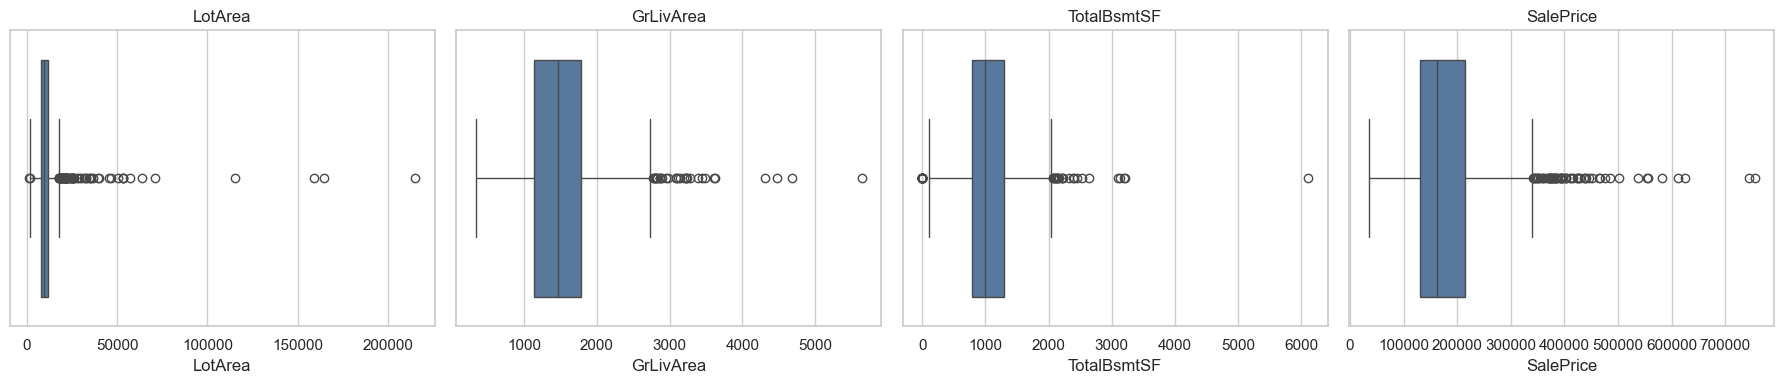

In [3]:
fig, axes = plt.subplots(1, len(features), figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(x=data[col], ax=ax, color="#4C78A8")
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 3. Split first and define explicit limits

The dictionaries below cap both tails for `LotArea` and `GrLivArea`, and only the upper tails for basement area and sale price. The values are examples, not claims about valid real-world limits. In a real project, record why every boundary was chosen.

In [4]:
X = data[features].copy()
X_train, X_test = train_test_split(X, test_size=0.30, random_state=0)
min_limits = {"LotArea": 1300, "GrLivArea": 334}
max_limits = {"LotArea": 50000, "GrLivArea": 4000, "TotalBsmtSF": 3000, "SalePrice": 600000}
capper = ArbitraryOutlierCapper(max_capping_dict=max_limits, min_capping_dict=min_limits)
capper.fit(X_train)
X_train_capped = capper.transform(X_train)
X_test_capped = capper.transform(X_test)
display(pd.DataFrame({"minimum cap": pd.Series(capper.left_tail_caps_), "maximum cap": pd.Series(capper.right_tail_caps_)}))

,minimum cap,maximum cap
GrLivArea,334.0,4000
LotArea,1300.0,50000
SalePrice,NaN,600000
TotalBsmtSF,NaN,3000


## 4. Compare before and after capping

Unlike trimming, arbitrary capping keeps the original number of rows. Values beyond a boundary become exactly equal to that boundary. The changed-value counts provide an audit trail.

,changed_rows
LotArea,7
GrLivArea,2
TotalBsmtSF,3
SalePrice,2


,raw_min,capped_min,raw_max,capped_max
LotArea,1300,1300,215245,50000
GrLivArea,334,334,4676,4000
TotalBsmtSF,0,0,3206,3000
SalePrice,34900,34900,755000,600000


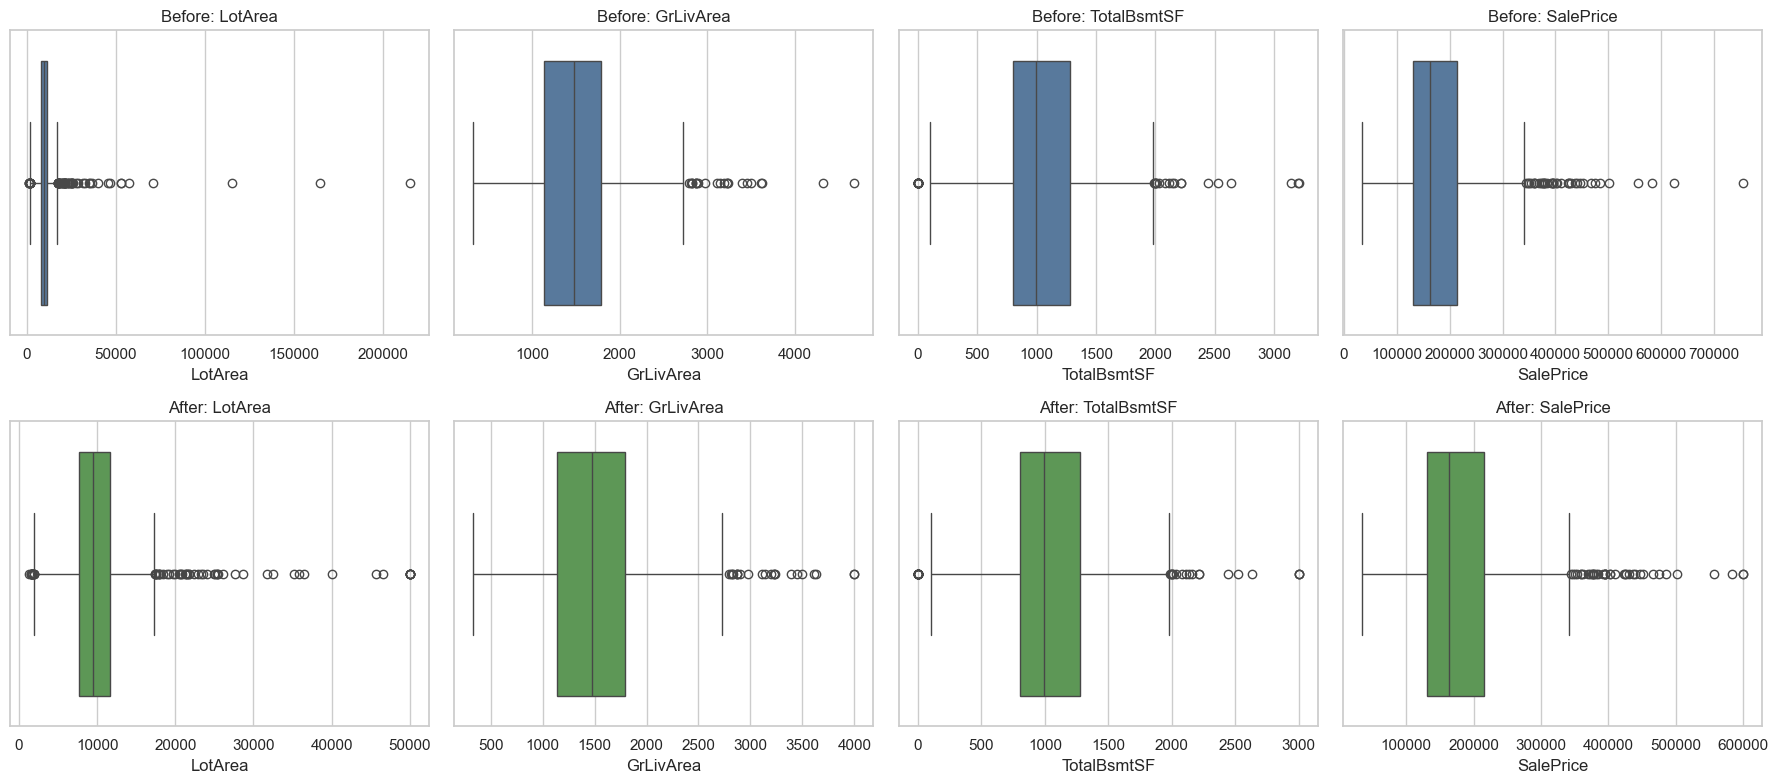

In [5]:
changed = (X_train[features] != X_train_capped[features]).sum().rename("changed_rows").to_frame()
display(changed)
display(pd.DataFrame({"raw_min": X_train.min(), "capped_min": X_train_capped.min(), "raw_max": X_train.max(), "capped_max": X_train_capped.max()}))
fig, axes = plt.subplots(2, len(features), figsize=(18, 8))
for i, col in enumerate(features):
    sns.boxplot(x=X_train[col], ax=axes[0, i], color="#4C78A8"); axes[0, i].set_title(f"Before: {col}")
    sns.boxplot(x=X_train_capped[col], ax=axes[1, i], color="#54A24B"); axes[1, i].set_title(f"After: {col}")
plt.tight_layout(); plt.show()

In [6]:
# Inspect rows affected by at least one cap.
affected = X_train.loc[(X_train[features] != X_train_capped[features]).any(axis=1), features].copy()
affected["changed_columns"] = (X_train[features] != X_train_capped[features]).loc[affected.index].sum(axis=1)
display(affected.head(10))

,LotArea,GrLivArea,TotalBsmtSF,SalePrice,changed_columns
1169,35760,3627,1930,625000,1
384,53107,1953,1580,240000,1
523,40094,4676,3138,184750,2
457,53227,1663,1364,256000,1
332,10655,1629,3206,284000,1
496,12692,3228,3200,430000,1
313,215245,2036,2136,375000,1
451,70761,1533,1533,280000,1
706,115149,1824,1643,302000,1
691,21535,4316,2444,755000,2


## Summary and cautions

Use `ArbitraryOutlierCapper` when limits come from a specification, policy, or meaningful physical/business constraint. It does not decide whether a value is an outlier. Review affected records, fit the transformer on training data only, and avoid arbitrary limits that erase valid variation. Missing values must be imputed or explicitly ignored before transformation.